### Spotify Analysis

In [1]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA

from sklearn.preprocessing import LabelEncoder
from sklearn.preprocessing import StandardScaler, MinMaxScaler, RobustScaler

In [2]:
csv = pd.read_csv(r"B:\MS-AI\MSAI-Projects\ML\songs\rolling_stones_spotify.csv")
df = pd.DataFrame(csv)

In [3]:
df.isnull().sum()

Unnamed: 0          0
name                0
album               0
release_date        0
track_number        0
id                  0
uri                 0
acousticness        0
danceability        0
energy              0
instrumentalness    0
liveness            0
loudness            0
speechiness         0
tempo               0
valence             0
popularity          0
duration_ms         0
dtype: int64

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1610 entries, 0 to 1609
Data columns (total 18 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Unnamed: 0        1610 non-null   int64  
 1   name              1610 non-null   str    
 2   album             1610 non-null   str    
 3   release_date      1610 non-null   str    
 4   track_number      1610 non-null   int64  
 5   id                1610 non-null   str    
 6   uri               1610 non-null   str    
 7   acousticness      1610 non-null   float64
 8   danceability      1610 non-null   float64
 9   energy            1610 non-null   float64
 10  instrumentalness  1610 non-null   float64
 11  liveness          1610 non-null   float64
 12  loudness          1610 non-null   float64
 13  speechiness       1610 non-null   float64
 14  tempo             1610 non-null   float64
 15  valence           1610 non-null   float64
 16  popularity        1610 non-null   int64  
 17  durati

### Dropping off unwanted columns

In [5]:
df.drop(columns=['Unnamed: 0', 'id', 'uri'], inplace=True)

### Type conversion

In [6]:
df['release_date'] =pd.to_datetime(df['release_date'])

In [7]:
df.shape

(1610, 15)

### Dropping the duplicates

In [8]:
df.drop_duplicates(inplace=True)

### Checking Outliers

In [9]:
df.columns

Index(['name', 'album', 'release_date', 'track_number', 'acousticness',
       'danceability', 'energy', 'instrumentalness', 'liveness', 'loudness',
       'speechiness', 'tempo', 'valence', 'popularity', 'duration_ms'],
      dtype='str')

### Accousticness

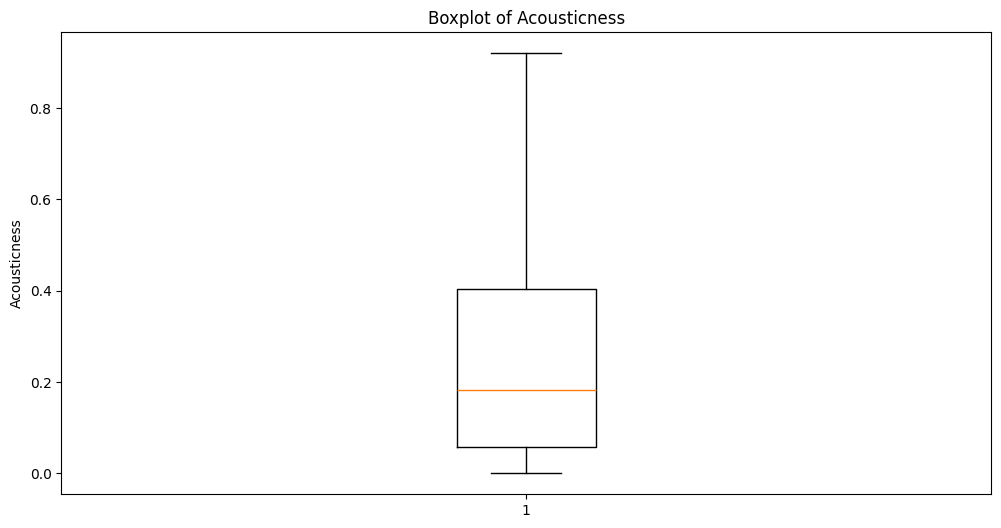

In [12]:
plt.figure(figsize=(12, 6))
plt.boxplot(df['acousticness'])
plt.title('Boxplot of Acousticness')
plt.ylabel('Acousticness')
plt.show()

In [11]:
# Treating the outliers
iqr = df['acousticness'].quantile(0.75) - df['acousticness'].quantile(0.25)
upperbound = df['acousticness'].quantile(0.75) + (1.5 * iqr)
lowerbound = df["acousticness"].quantile(0.25) - (1.5 * iqr)

df["acousticness"] = df["acousticness"].clip(lower=lowerbound, upper=upperbound)

### Danceability

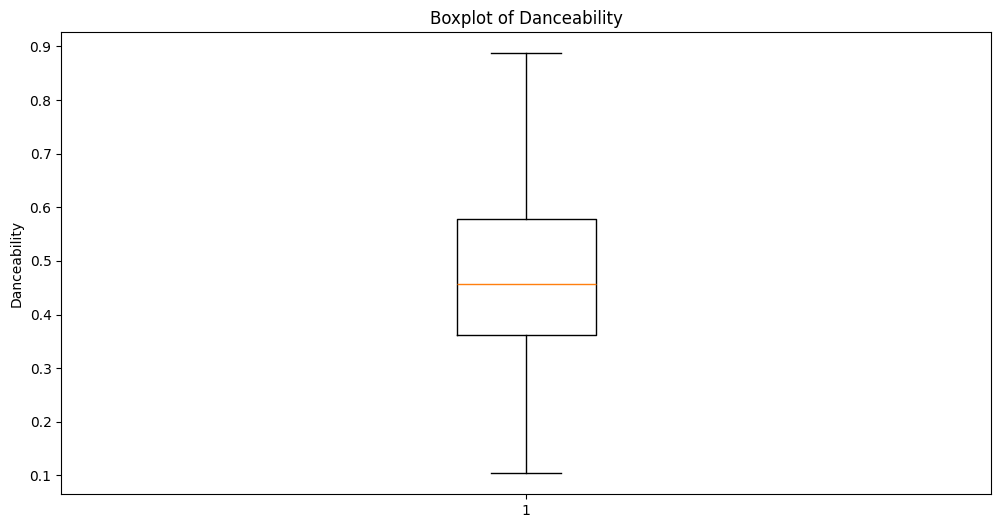

In [13]:
plt.figure(figsize=(12, 6))
plt.boxplot(df['danceability'])
plt.title('Boxplot of Danceability')
plt.ylabel('Danceability')
plt.show()

### Energy

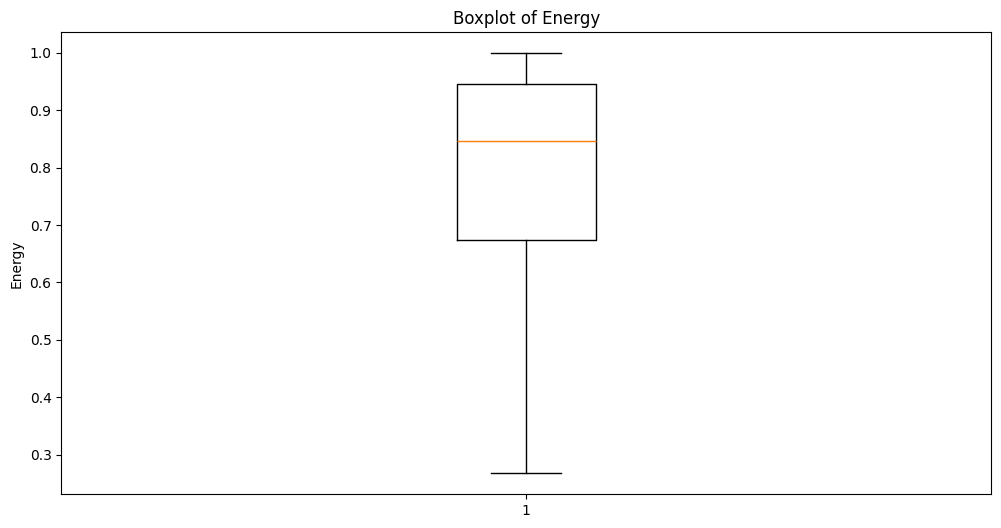

In [16]:
plt.figure(figsize=(12, 6))
plt.boxplot(df['energy'])
plt.title('Boxplot of Energy')
plt.ylabel('Energy')
plt.show()

In [15]:
iqrenergy = df['energy'].quantile(0.75) - df['energy'].quantile(0.25)
upperboundenergy = df['energy'].quantile(0.75) + (1.5 * iqrenergy)
lowerboundenergy = df['energy'].quantile(0.25) - (1.5 * iqrenergy)

df['energy'] = df['energy'].clip(lower=lowerboundenergy, upper=upperboundenergy)

### Instrumentalness

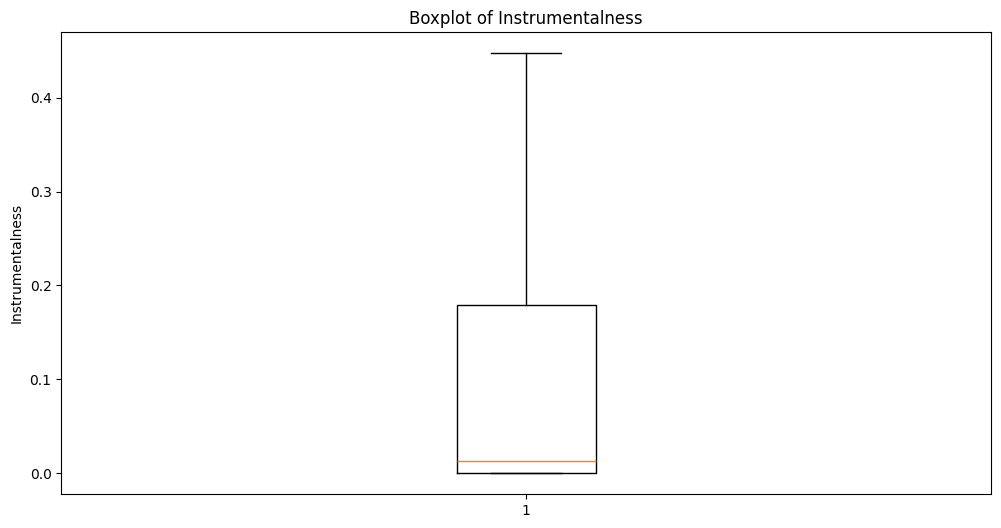

In [18]:
plt.figure(figsize=(12, 6))
plt.boxplot(df['instrumentalness'])
plt.title('Boxplot of Instrumentalness')
plt.ylabel('Instrumentalness')
plt.show()

In [17]:
iqrinstrument = df['instrumentalness'].quantile(0.75) - df['instrumentalness'].quantile(0.25)
upperboundinstrument = df['instrumentalness'].quantile(0.75) + (1.5 * iqrinstrument)
lowerboundinstrument = df['instrumentalness'].quantile(0.25) - (1.5 * iqrinstrument)

df['instrumentalness'] = df['instrumentalness'].clip(lower=lowerboundinstrument, upper=upperboundinstrument)

### Liveness

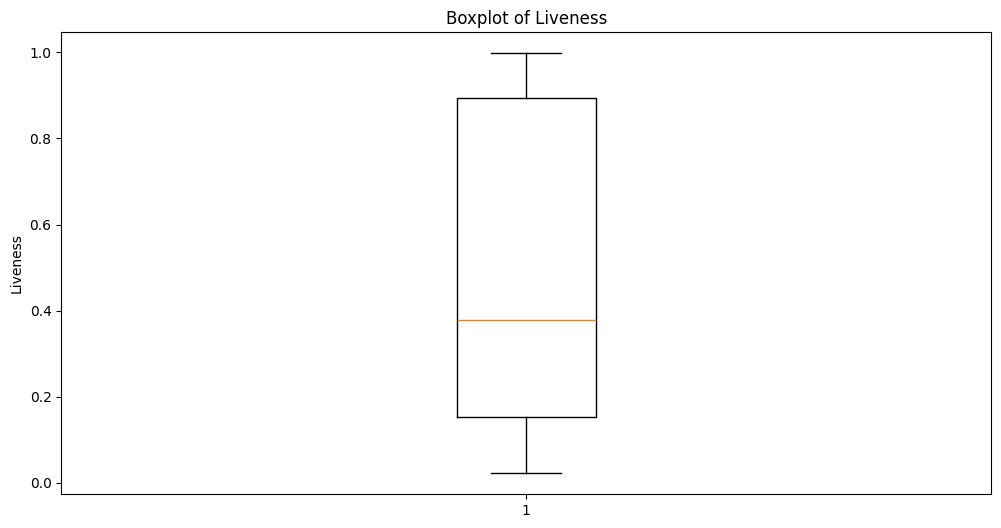

In [19]:
plt.figure(figsize=(12, 6))
plt.boxplot(df['liveness'])
plt.title('Boxplot of Liveness')
plt.ylabel('Liveness')
plt.show()

### Loudness

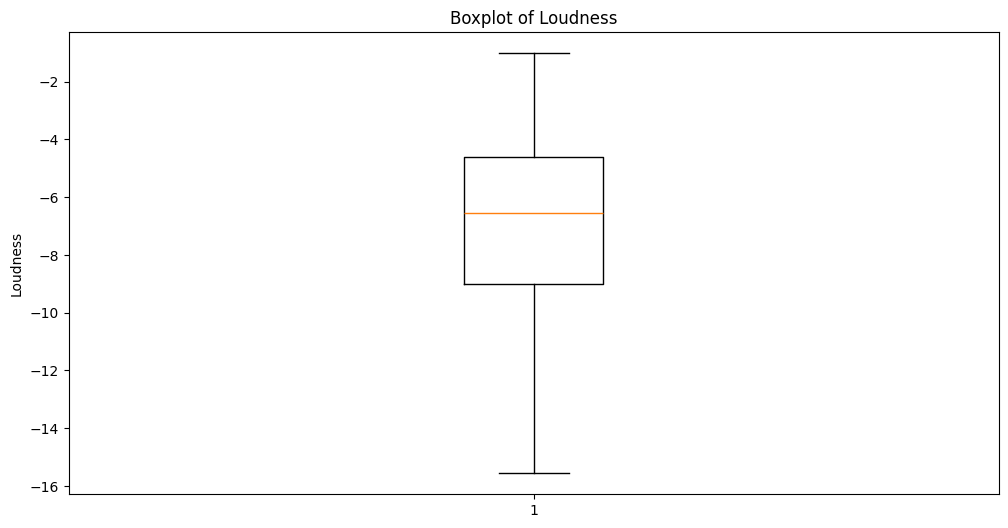

In [22]:
plt.figure(figsize=(12, 6))
plt.boxplot(df['loudness'])
plt.title('Boxplot of Loudness')
plt.ylabel('Loudness')
plt.show()

In [21]:
iqrloudness = df['loudness'].quantile(0.75) - df['loudness'].quantile(0.25)
upperboundloudness = df['loudness'].quantile(0.75) + (1.5 * iqrloudness)
lowerboundloudness = df['loudness'].quantile(0.25) - (1.5 * iqrloudness)

df['loudness'] = df['loudness'].clip(lower=lowerboundloudness, upper=upperboundloudness)

### Speechiness

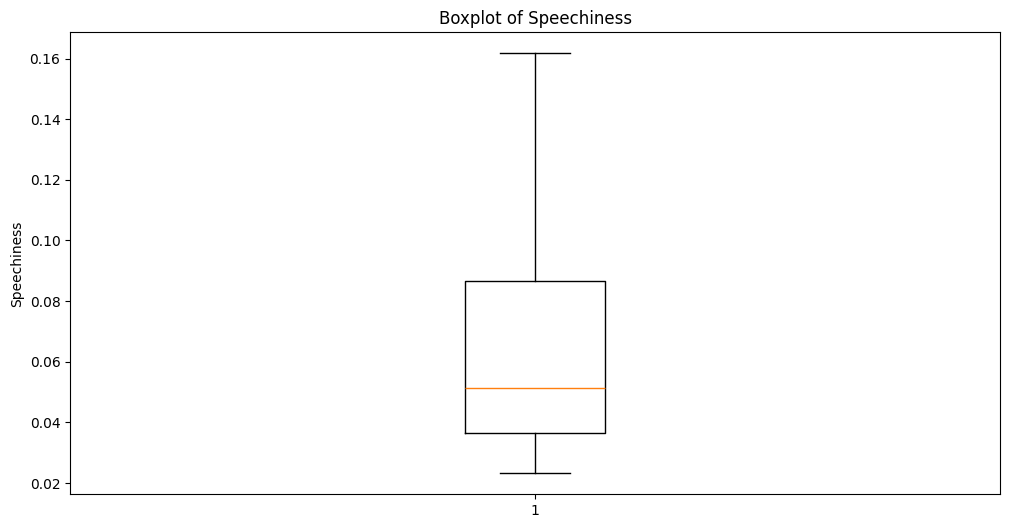

In [25]:
plt.figure(figsize=(12, 6))
plt.boxplot(df['speechiness'])
plt.title('Boxplot of Speechiness')
plt.ylabel('Speechiness')
plt.show()

In [24]:
iqrspeechiness = df['speechiness'].quantile(0.75) - df['speechiness'].quantile(0.25)
upperboundspeechiness = df['speechiness'].quantile(0.75) + (1.5 * iqrspeechiness)
lowerboundspeechiness = df['speechiness'].quantile(0.25) - (1.5 * iqrspeechiness)

df['speechiness'] = df['speechiness'].clip(lower=lowerboundspeechiness, upper=upperboundspeechiness)

### Tempo

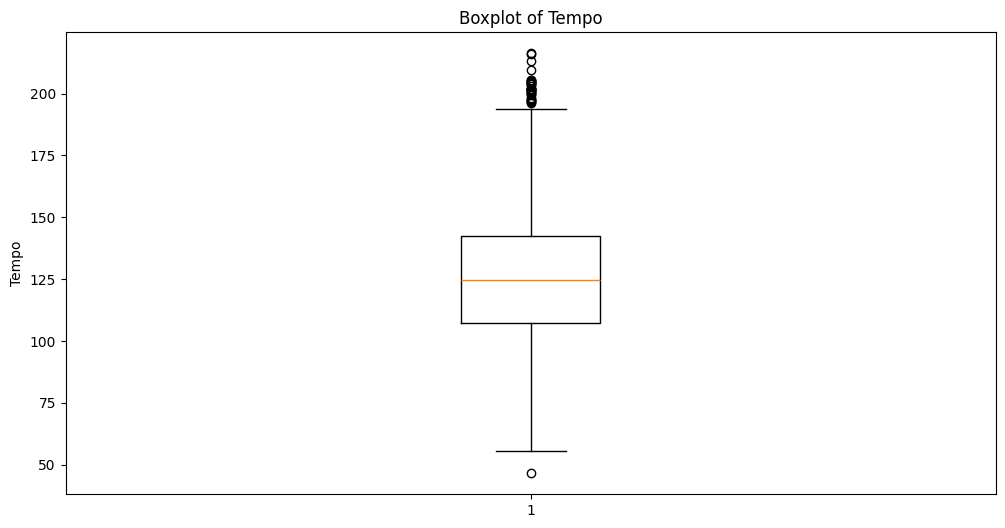

In [26]:
plt.figure(figsize=(12, 6))
plt.boxplot(df['tempo'])
plt.title('Boxplot of Tempo')
plt.ylabel('Tempo')
plt.show()

In [27]:
iqrtempo = df['tempo'].quantile(0.75) - df['tempo'].quantile(0.25)
upperboundtempo = df['tempo'].quantile(0.75) + (1.5 * iqrtempo)
lowerboundtempo = df['tempo'].quantile(0.25) - (1.5 * iqrtempo)

df['tempo'] = df['tempo'].clip(lower=lowerboundtempo, upper=upperboundtempo)

### Valence

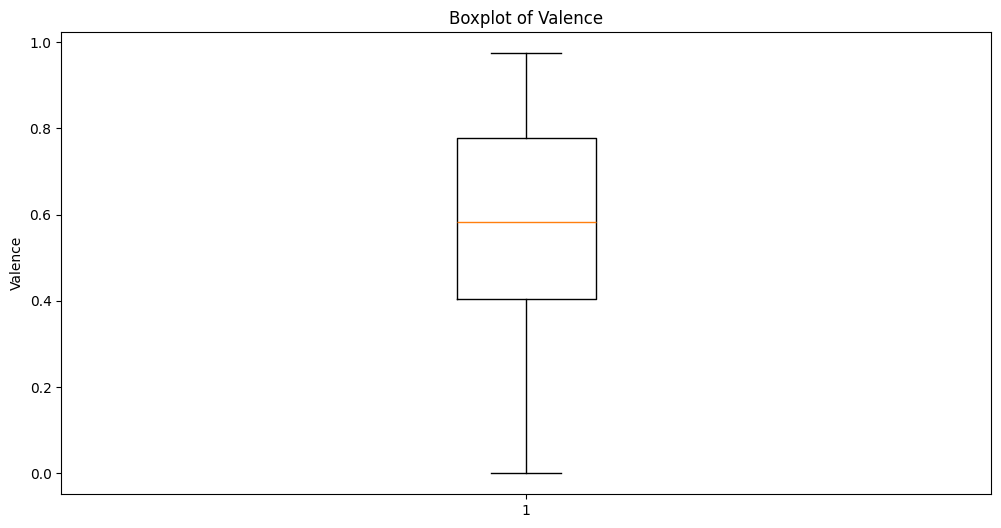

In [28]:
plt.figure(figsize=(12, 6))
plt.boxplot(df['valence'])
plt.title('Boxplot of Valence')
plt.ylabel('Valence')
plt.show()

### Popularity

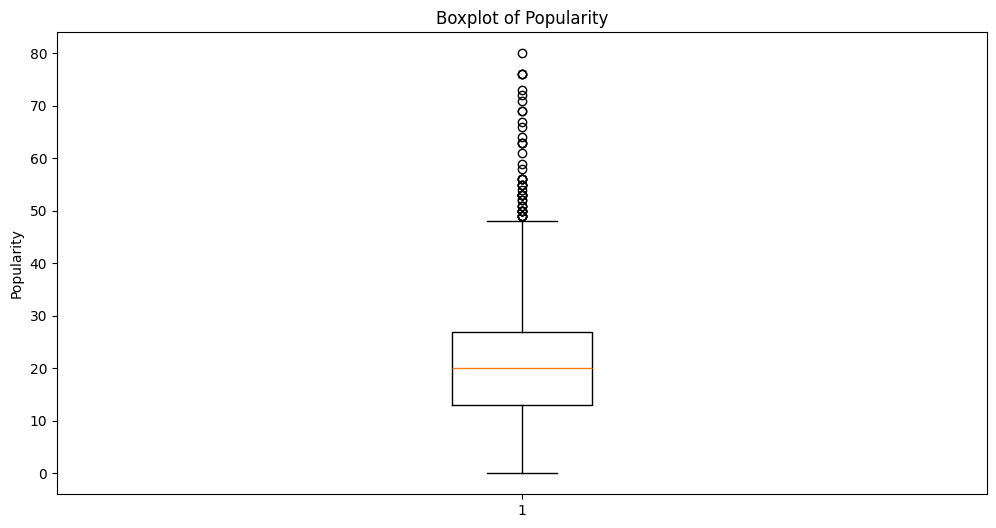

In [ ]:
plt.figure(figsize=(12, 6))
plt.boxplot(df['popularity'])
plt.title('Boxplot of Popularity')
plt.ylabel('Popularity')
plt.show()

### Refining the data for further processing

In [30]:
df['album'].unique()

<StringArray>
[                                                             'Licked Live In NYC',
                                                          'Live At The El Mocambo',
                                                       'Tattoo You (Super Deluxe)',
                                                                      'Tattoo You',
                                                            'A Bigger Bang (Live)',
                                                               'Steel Wheels Live',
                                                        'Goats Head Soup (Deluxe)',
                                                  'Bridges To Buenos Aires (Live)',
                                                        'Bridges To Bremen (Live)',
                                                                   'Honk (Deluxe)',
                                                      'Voodoo Lounge Uncut (Live)',
                              'From The Vault: No Security - S

In [31]:
df["album"] = df['album'].str.replace(r"December[’']s Children \(And Everybody[’']s\)", "December's Children (and everybody's)", regex=True, case=False)
df["album"] = df['album'].str.replace(r"England[’']s Newest HitMakers", "England's Newest Hit Makers", regex=True, case=False)
df["album"] = df['album'].str.replace(r"Out Of Our Heads \(UK\)", "Out Of Our Heads (UK Sequence)", regex=True, case=False)
df["album"] = df['album'].str.replace("got LIVE if you want it!", "Got Live if you want it!", regex=True, case=False)
df["album"] = df['album'].str.replace("12 X 5", "12 x 5", regex=True, case=False)

### Most popular album based on popularity score above 40

In [32]:
groupedData =df.loc[df['popularity'] >= 50].groupby("album")["popularity"].mean().sort_values(ascending=False)
groupedData

album
Aftermath                                     72.000000
Beggars Banquet (50th Anniversary Edition)    64.500000
Some Girls                                    64.000000
Tattoo You (2009 Re-Mastered)                 63.333333
Goats Head Soup (Remastered 2009)             62.000000
Bridges To Babylon (Remastered)               61.000000
Let It Bleed                                  60.750000
Out Of Our Heads                              60.666667
Sticky Fingers (Remastered)                   60.000000
Between The Buttons                           58.000000
Exile On Main Street (2010 Re-Mastered)       56.000000
December's Children (and everybody's)         55.500000
It's Only Rock 'N' Roll (2009 Re-Mastered)    55.000000
Emotional Rescue (2009 Re-Mastered)           54.500000
Voodoo Lounge (Remastered 2009)               53.000000
Black And Blue (Remastered 2009)              53.000000
Aftermath (UK Version)                        52.000000
The Rolling Stones                        

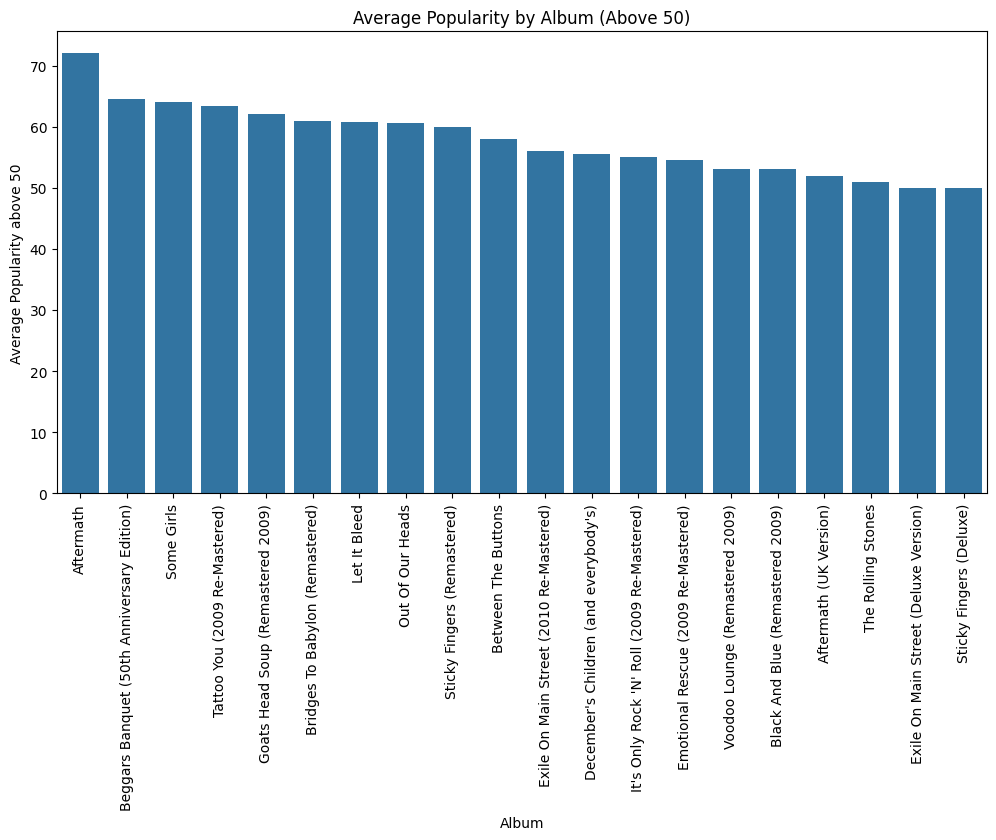

In [34]:
plt.figure(figsize=(12, 6))
sns.barplot(x=groupedData.index, y=groupedData.values)
plt.title('Average Popularity by Album (Above 50)')
plt.xlabel('Album')
plt.ylabel('Average Popularity above 50')
plt.xticks(rotation=90)
plt.show()

### Most popular album based on popularity score above 40

In [35]:
groupedData =df.loc[df["popularity"]>=50].groupby("album")["popularity"].count().sort_values(ascending=False)
groupedData

album
Sticky Fingers (Remastered)                   6
Exile On Main Street (2010 Re-Mastered)       4
Let It Bleed                                  4
Some Girls                                    3
Out Of Our Heads                              3
Tattoo You (2009 Re-Mastered)                 3
Beggars Banquet (50th Anniversary Edition)    2
Aftermath                                     2
December's Children (and everybody's)         2
Between The Buttons                           2
Goats Head Soup (Remastered 2009)             2
Emotional Rescue (2009 Re-Mastered)           2
Aftermath (UK Version)                        1
Exile On Main Street (Deluxe Version)         1
Bridges To Babylon (Remastered)               1
Black And Blue (Remastered 2009)              1
It's Only Rock 'N' Roll (2009 Re-Mastered)    1
Sticky Fingers (Deluxe)                       1
The Rolling Stones                            1
Voodoo Lounge (Remastered 2009)               1
Name: popularity, dtype: int64

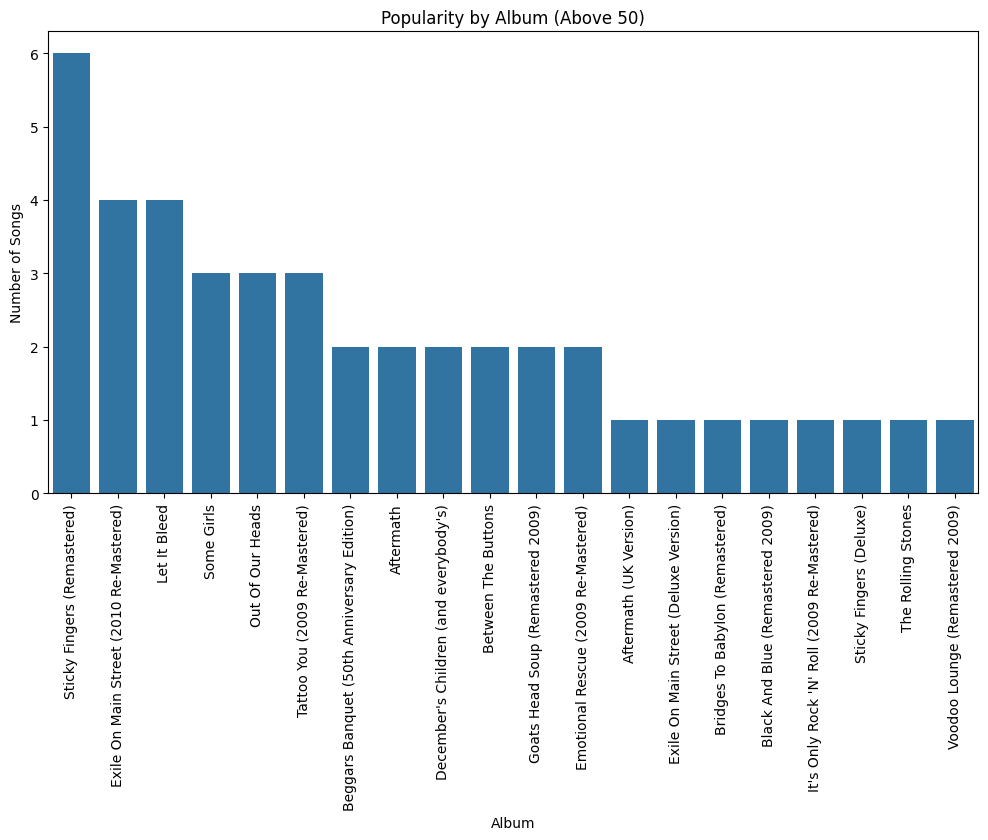

In [36]:
plt.figure(figsize=(12, 6))
sns.barplot(x=groupedData.index, y=groupedData.values)
plt.title('Popularity by Album (Above 50)')
plt.xlabel('Album')
plt.ylabel('Number of Songs')
plt.xticks(rotation=90)
plt.show()

### Multicolinarity

### Feature Engineering

In [37]:
df["year"] = df["release_date"].dt.year
df["month"] = df["release_date"].dt.month
df["week"] = df["release_date"].dt.isocalendar().week

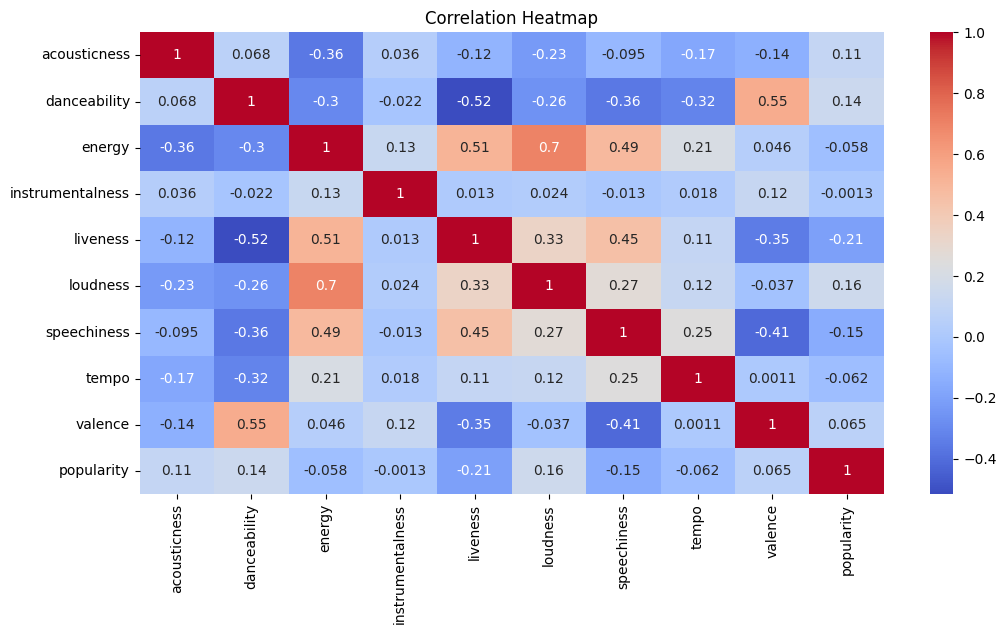

In [38]:
plt.figure(figsize=(12, 6))
sns.heatmap(df.drop(columns=["release_date",'name', 'album',"track_number", "year", "month", "week", "duration_ms"]).corr(), annot=True, cmap='coolwarm')
plt.title('Correlation Heatmap')
plt.show()

Loudness and energy correlation score are 0.7

In [39]:
songFeatures = df.loc[df["popularity"] >= 50, ["album", "energy", "loudness", "popularity", "valence", "danceability", "liveness", "year", "month", "week"]]
songFeatures.head()

,album,energy,loudness,popularity,valence,danceability,liveness,year,month,week
684,Bridges To Babylon (Remastered),0.742,-4.363,61,0.470,0.605,0.2560,1997,9,40
724,Voodoo Lounge (Remastered 2009),0.855,-5.116,53,0.511,0.530,0.0628,1994,7,28
862,Tattoo You (2009 Re-Mastered),0.932,-4.142,76,0.971,0.631,0.0918,1981,8,35
870,Tattoo You (2009 Re-Mastered),0.459,-9.292,55,0.119,0.617,0.2850,1981,8,35
872,Tattoo You (2009 Re-Mastered),0.794,-6.042,59,0.911,0.606,0.5680,1981,8,35


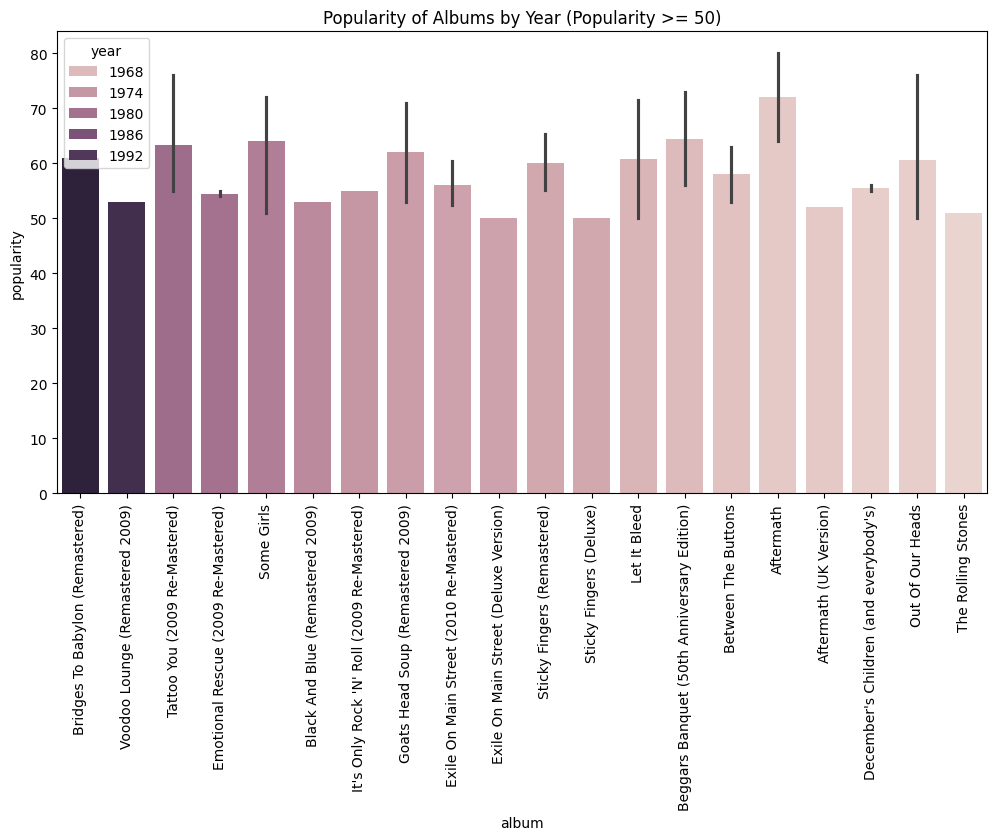

In [40]:
plt.figure(figsize=(12, 6))
sns.barplot(x=songFeatures['album'], y=songFeatures['popularity'], hue=songFeatures['year'])
plt.title('Popularity of Albums by Year (Popularity >= 50)')
plt.xticks(rotation=90)
plt.show()

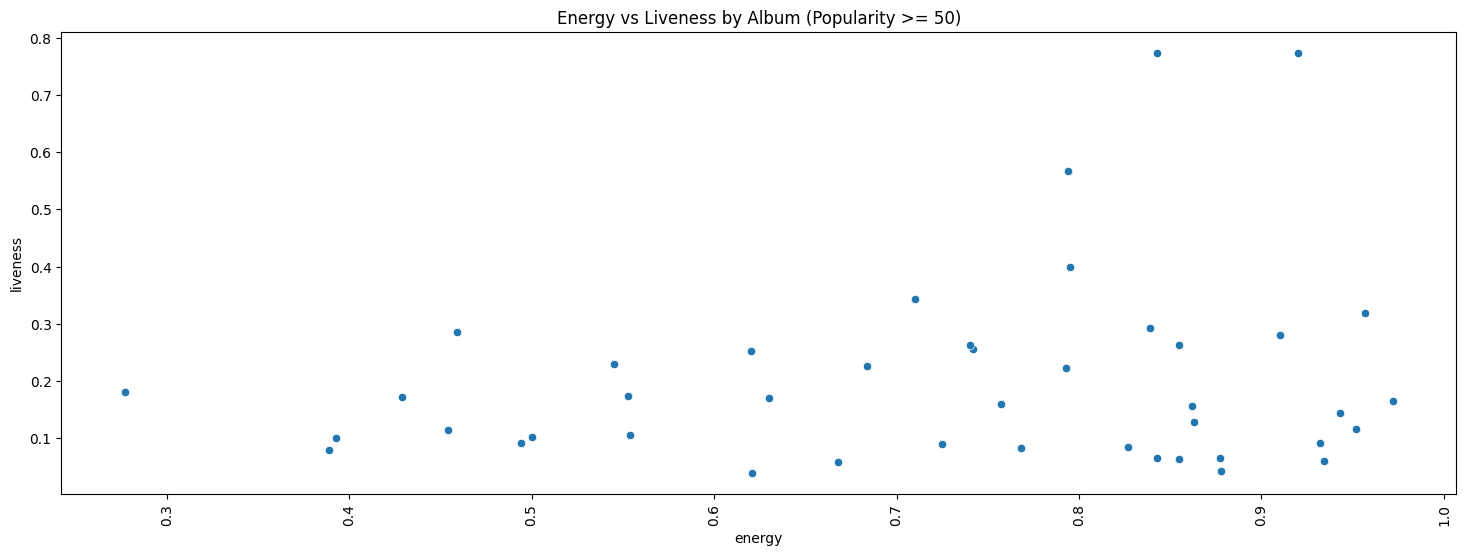

In [42]:
plt.figure(figsize=(18, 6))
sns.scatterplot(data=songFeatures, x='energy', y='liveness')
plt.title('Energy vs Liveness by Album (Popularity >= 50)')
plt.xticks(rotation=90)
plt.show()

### Inferences: According to the correlation chart, valence and danceability score was 0.55 and also below chart it shows on 50% popularity threshold.
- The (valence score) balance of happy, cheerful, and euphoria type of songs let the danceability score raise more, people tends to dances on songs which has a balance valence score. 

In [43]:
songfeat_val_dance = df.loc[(df["popularity"] >= 50) & (df["valence"]> 0.5) & (df["danceability"] > 0.5) , ["album", "energy", "loudness", "popularity", "valence", "danceability", "liveness", "year", "month", "week"]]
songfeat_val_dance.head()

,album,energy,loudness,popularity,valence,danceability,liveness,year,month,week
724,Voodoo Lounge (Remastered 2009),0.855,-5.116,53,0.511,0.530,0.0628,1994,7,28
862,Tattoo You (2009 Re-Mastered),0.932,-4.142,76,0.971,0.631,0.0918,1981,8,35
872,Tattoo You (2009 Re-Mastered),0.794,-6.042,59,0.911,0.606,0.5680,1981,8,35
880,Emotional Rescue (2009 Re-Mastered),0.621,-5.478,54,0.776,0.678,0.0394,1980,6,25
881,Emotional Rescue (2009 Re-Mastered),0.843,-5.315,55,0.841,0.756,0.0654,1980,6,25


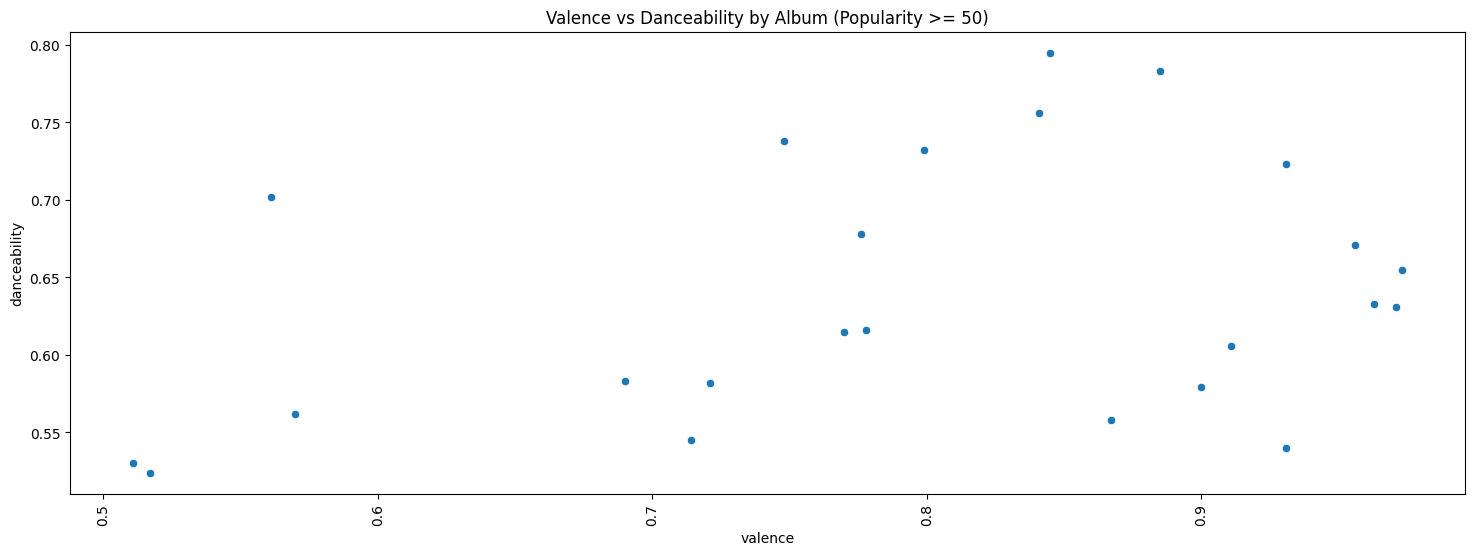

In [44]:
plt.figure(figsize=(18, 6))
sns.scatterplot(data=songfeat_val_dance, x='valence', y='danceability')
plt.title('Valence vs Danceability by Album (Popularity >= 50)')
plt.xticks(rotation=90)
plt.show()

In [45]:
songfeat_eng_loud = df.loc[(df["popularity"] >= 50), ["energy", "loudness"]]
songfeat_eng_loud.head()

,energy,loudness
684,0.742,-4.363
724,0.855,-5.116
862,0.932,-4.142
870,0.459,-9.292
872,0.794,-6.042


### Inferences: According to the below chart, users feels more energitic (energy score) when they hear heavier sounds (loudness score).

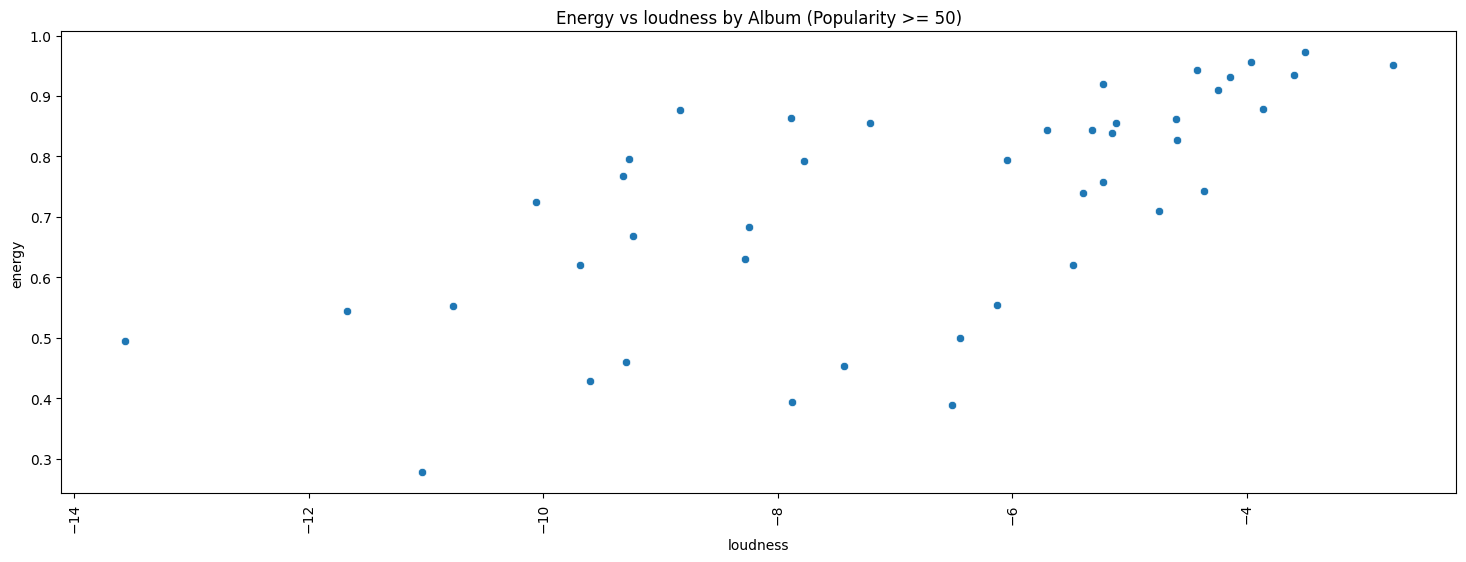

In [46]:
plt.figure(figsize=(18, 6))
sns.scatterplot(data=songfeat_eng_loud, x='loudness', y='energy')
plt.title('Energy vs loudness by Album (Popularity >= 50)')
plt.xticks(rotation=90)
plt.show()

In [47]:
songpopularity_features = df[["energy", "loudness", "valence", "acousticness", "danceability", "liveness", "tempo", "speechiness","popularity", "year"]].sort_values(by="popularity", ascending=False)
songpopularity_features

,energy,loudness,valence,acousticness,danceability,liveness,tempo,speechiness,popularity,year
1403,0.795,-9.267,0.612,0.0493,0.464,0.3990,158.691,0.09260,80,1966
862,0.932,-4.142,0.971,0.0436,0.631,0.0918,122.429,0.03540,76,1981
1472,0.863,-7.890,0.931,0.0383,0.723,0.1280,136.302,0.03380,76,1965
1248,0.630,-8.277,0.489,0.4470,0.634,0.1700,118.628,0.03100,76,1969
1257,0.668,-9.237,0.561,0.5180,0.702,0.0588,116.063,0.16175,73,1968
...,...,...,...,...,...,...,...,...,...,...
1595,0.783,-7.981,0.842,0.3120,0.783,0.0763,97.018,0.07410,0,1964
1589,0.368,-10.734,0.470,0.1360,0.628,0.1700,87.178,0.10800,0,1964
1590,0.685,-7.793,0.950,0.0441,0.672,0.2380,97.854,0.02920,0,1964
1591,0.731,-8.731,0.903,0.0141,0.475,0.1610,87.559,0.05540,0,1964


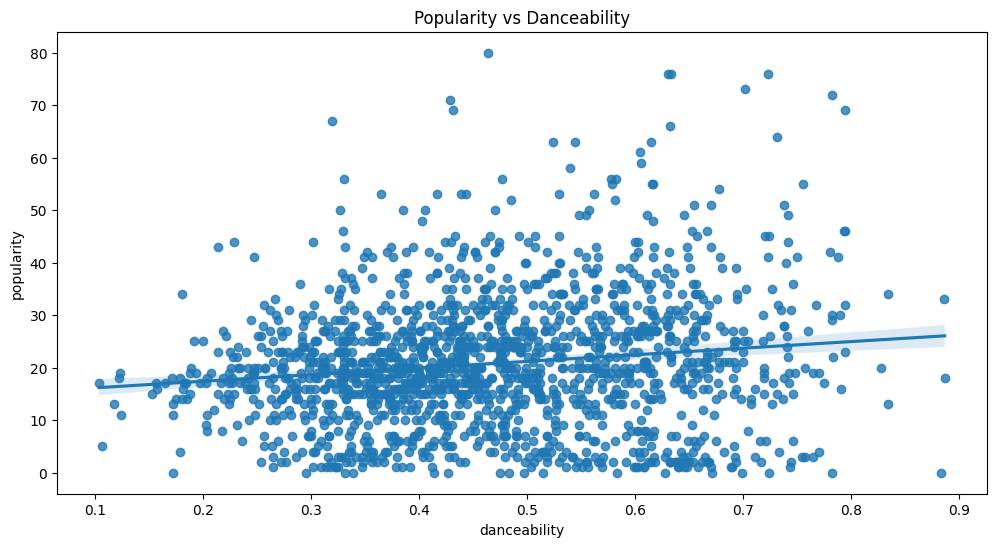

In [49]:
plt.figure(figsize=(12, 6))
sns.regplot(data=songpopularity_features, x='danceability', y='popularity', )
plt.title('Popularity vs Danceability')
plt.show()

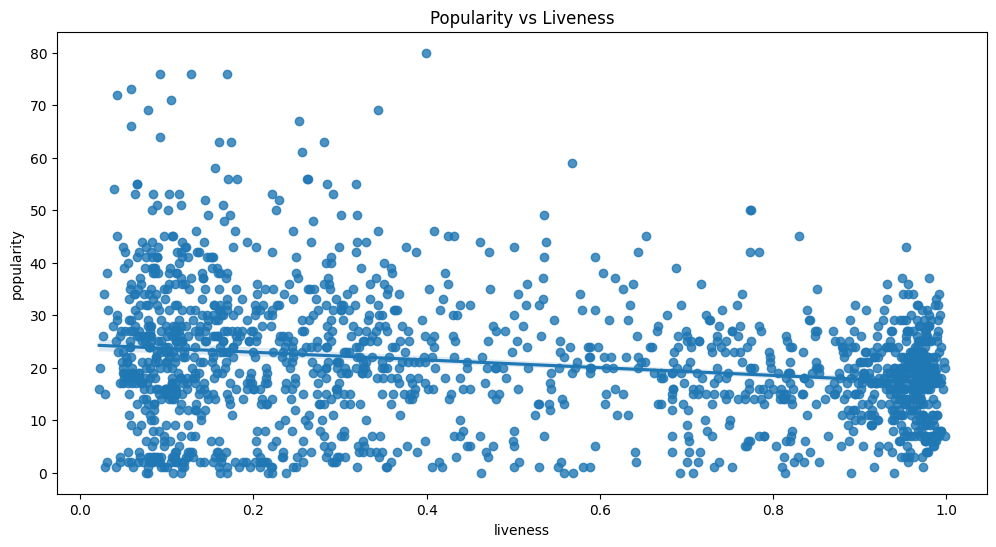

In [50]:
plt.figure(figsize=(12, 6))
sns.regplot(data=songpopularity_features, x='liveness', y='popularity', )
plt.title('Popularity vs Liveness')
plt.show()

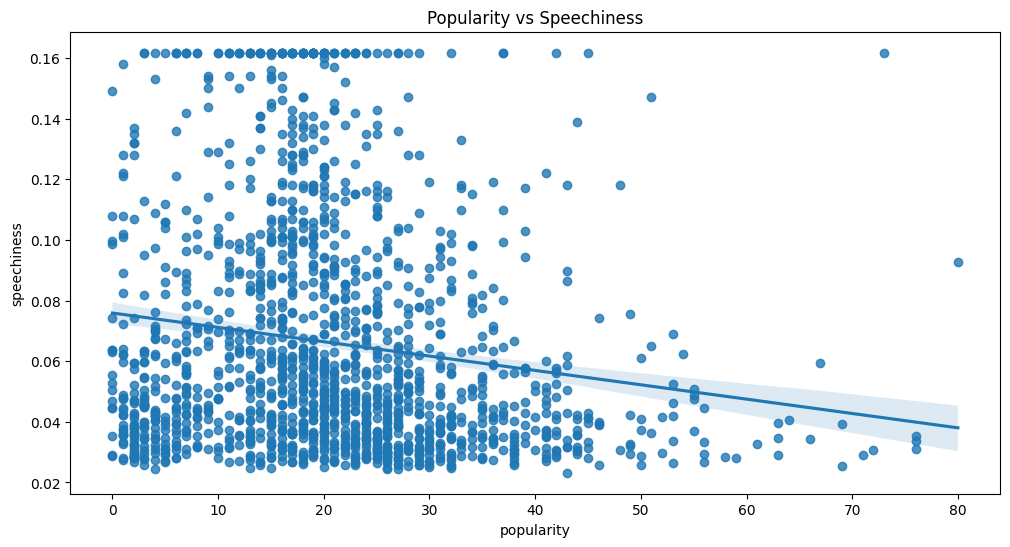

In [51]:
plt.figure(figsize=(12, 6))
sns.regplot(data=songpopularity_features, x='popularity', y='speechiness', )
plt.title('Popularity vs Speechiness')
plt.show()

### Data with average popularity

In [52]:
filteryearlyData = df.groupby("year")[["popularity","tempo","speechiness", "valence", "energy", "loudness", "acousticness", "danceability", "liveness"]].mean().reset_index()
filteryearlyData

,year,popularity,tempo,speechiness,valence,energy,loudness,acousticness,danceability,liveness
0,1964,18.250000,119.393552,0.058872,0.742517,0.675067,-9.659767,0.177801,0.599050,0.202080
1,1965,17.611111,126.719435,0.042606,0.718732,0.673889,-9.259250,0.188233,0.566519,0.225047
2,1966,17.428571,129.933897,0.057321,0.601410,0.698317,-10.860565,0.212934,0.493857,0.375959
3,1967,17.382353,123.882438,0.055098,0.546275,0.641137,-9.871576,0.377005,0.514490,0.211247
4,1968,28.500000,120.952550,0.053785,0.496390,0.608500,-9.399200,0.306190,0.497750,0.134775
5,1969,34.962963,121.504889,0.045800,0.617778,0.627370,-9.811111,0.493443,0.493815,0.173722
6,1970,19.361702,121.509170,0.053070,0.648070,0.756936,-8.661040,0.183281,0.464319,0.758957
7,1971,28.079365,129.434905,0.052974,0.549730,0.756063,-5.328206,0.327171,0.449143,0.304787
8,1972,23.716049,122.629398,0.041653,0.717358,0.788123,-5.977998,0.429199,0.460506,0.312304
9,1973,30.350000,112.567400,0.037020,0.641500,0.676600,-7.884900,0.553935,0.451300,0.296925


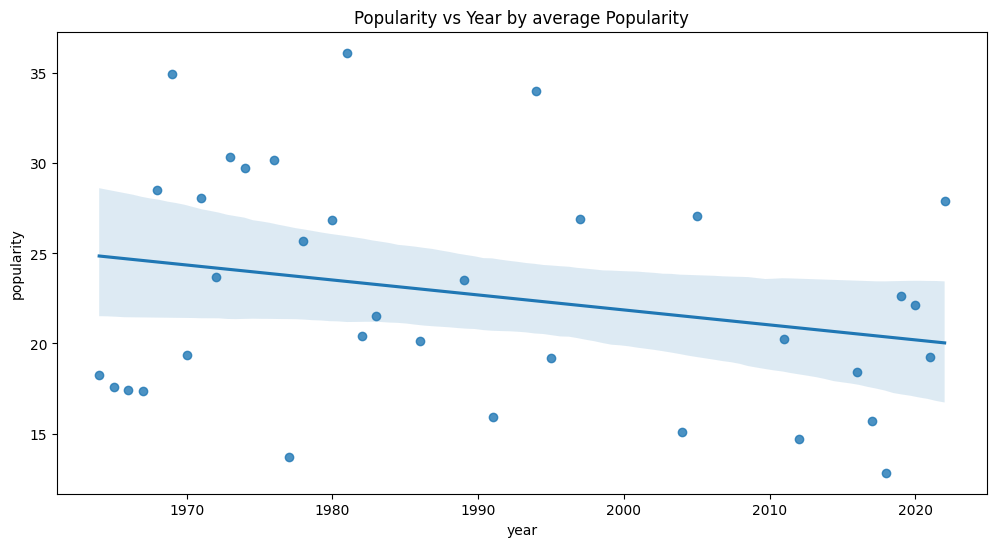

In [53]:
plt.figure(figsize=(12, 6))
sns.regplot(data=filteryearlyData, x='year', y='popularity')
plt.title('Popularity vs Year by average Popularity')
plt.show()

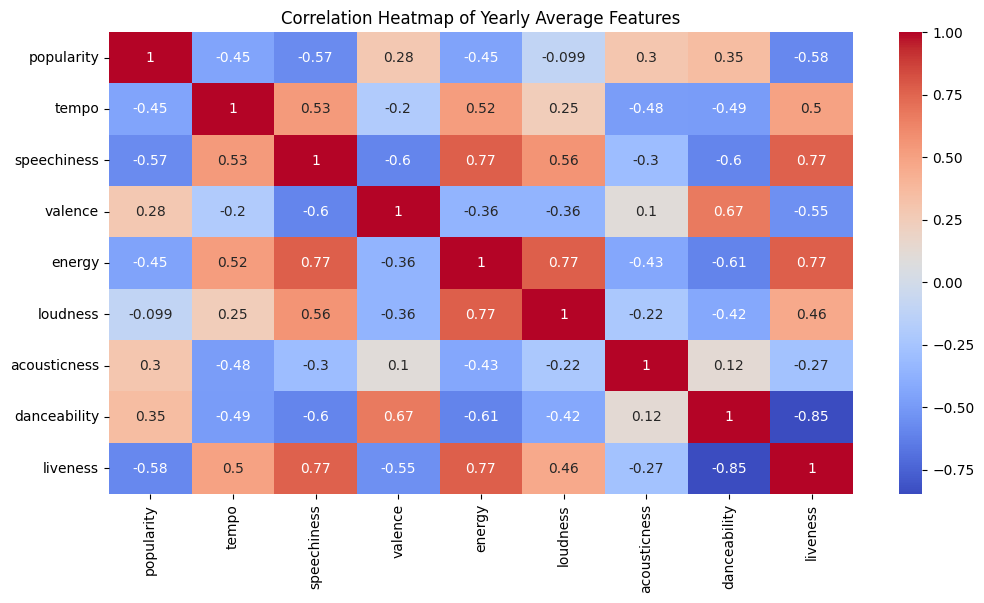

In [54]:
plt.figure(figsize=(12, 6))
sns.heatmap(filteryearlyData.drop(columns=["year"]).corr(), annot=True, cmap='coolwarm')
plt.title('Correlation Heatmap of Yearly Average Features')
plt.show()

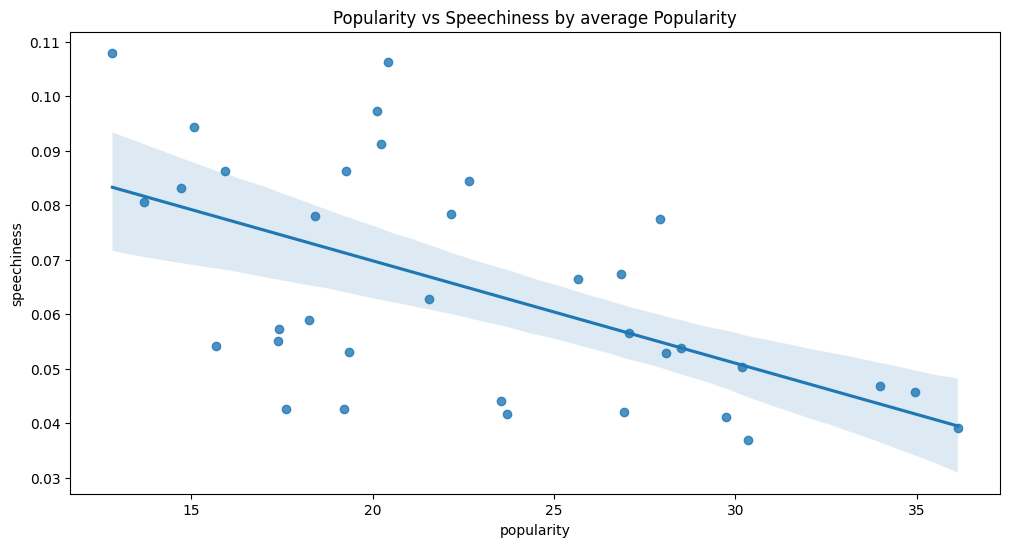

In [55]:
plt.figure(figsize=(12, 6))
sns.regplot(data=filteryearlyData, x='popularity', y='speechiness', )
plt.title('Popularity vs Speechiness by average Popularity')
plt.show()

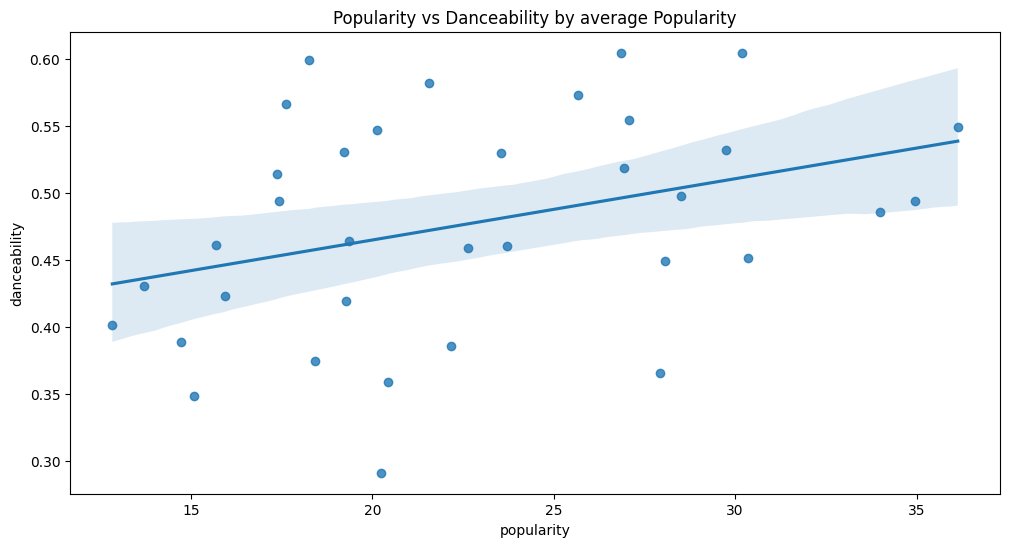

In [56]:
plt.figure(figsize=(12, 6))
sns.regplot(data=filteryearlyData, x='popularity', y='danceability', )
plt.title('Popularity vs Danceability by average Popularity')
plt.show()

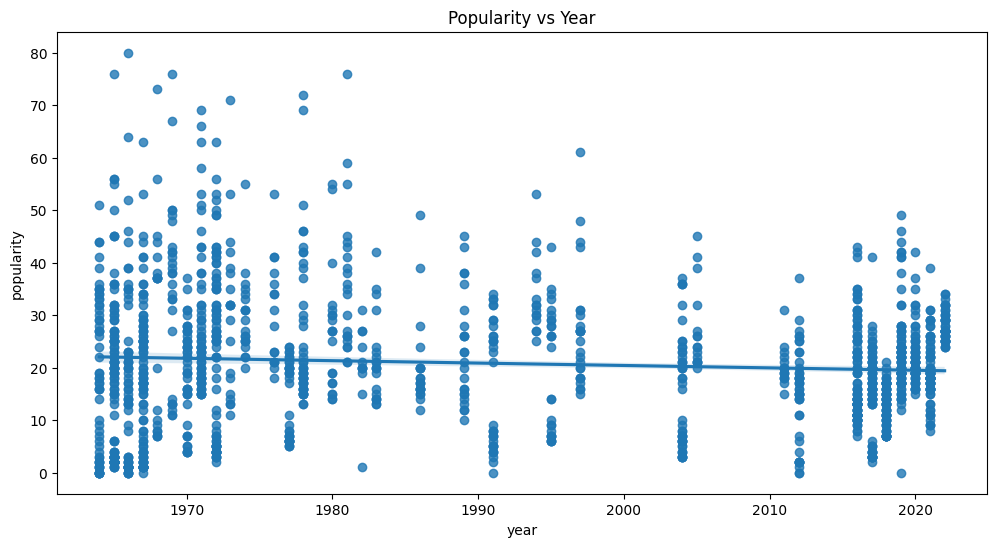

In [57]:
plt.figure(figsize=(12, 6))
sns.regplot(data=songpopularity_features, x='year', y='popularity', )
plt.title('Popularity vs Year')
plt.show()

### Encoding
- Real name and album remains untouched

In [ ]:
df["name_encoded"] = LabelEncoder().fit_transform(df["name"])
df["album_encoded"] = LabelEncoder().fit_transform(df["album"])

### Data Scaling for dimensionality reduction

In [ ]:
# Scaling the features before reducing the dimensionality
stdscaler = StandardScaler()
minmaxscaler = MinMaxScaler()
robustscaler = RobustScaler()

# * Implementing standart scaling into the features
df["acousticness"] = stdscaler.fit_transform(df[["acousticness"]])
df["energy"] = stdscaler.fit_transform(df[["energy"]])
df["danceability"] = stdscaler.fit_transform(df[["danceability"]])
df["instrumentalness"] = stdscaler.fit_transform(df[["instrumentalness"]])
df["liveness"] = stdscaler.fit_transform(df[["liveness"]])
df["loudness"] = stdscaler.fit_transform(df[["loudness"]])
df["speechiness"] = stdscaler.fit_transform(df[["speechiness"]])
df["tempo"] = stdscaler.fit_transform(df[["tempo"]])
df["valence"] = stdscaler.fit_transform(df[["valence"]])
df["popularity"] = stdscaler.fit_transform(df[["popularity"]])
df["duration_ms"] = stdscaler.fit_transform(df[["duration_ms"]])